In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sns.set_style('whitegrid')


In [3]:
data = pd.read_csv('/home/mohmmad/zahra/daneshkar/tamrin_daneshkar/football_player_rating_dataset (1).csv') 

print("Shape:", data.shape)

data.head()


Shape: (173587, 63)


,match_id,match_date,league_id,league_name,country_code,parent_league_name,parent_league_season,home_team_id,home_team_name,away_team_id,away_team_name,home_score,away_score,is_home_team,team_goals,opponent_goals,goal_difference,team_result,player_id,player_name,team_id,team_name,is_goalkeeper,player_rating,minutes_played,goals,assists,shots_on_target,blocked_shots,expected_assists,xg_plus_xa,chances_created,touches,touches_opp_box,successful_dribbles,dribble_attempts,dribble_success_rate,accurate_passes,total_passes,pass_accuracy,passes_final_third,accurate_crosses,cross_attempts,cross_success_rate,accurate_long_balls,long_ball_attempts,long_ball_success_rate,tackles_won,interceptions,clearances,defensive_actions,recoveries,dribbled_past,duels_won,duels_lost,ground_duels_won,ground_duel_attempts,ground_duel_success_rate,aerial_duels_won,aerial_duel_attempts,aerial_duel_success_rate,fouls_committed,was_fouled
0,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,452269,Lucas Evangelista,109705,Bragantino,0,7.16,89.0,0.0,0.0,0.0,1.0,NaN,NaN,2.0,64,1.0,1.0,1.0,100.0,35,47,74.500000,6.0,2.0,10.0,20.0,0.0,3.0,0.000000,2,0,0,2,2,0.0,4.0,NaN,4.0,4.0,100.000000,0.0,0.0,NaN,0,1.0
1,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,612191,André Cardoso,109705,Bragantino,0,6.41,11.0,0.0,0.0,NaN,0.0,NaN,NaN,0.0,21,0.0,NaN,NaN,NaN,15,17,88.199997,2.0,NaN,NaN,NaN,4.0,5.0,80.000000,3,0,0,3,1,0.0,3.0,2.0,3.0,5.0,60.000000,0.0,0.0,NaN,1,NaN
2,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,768389,Cleiton Schwengber,109705,Bragantino,1,6.79,90.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46,NaN,NaN,NaN,NaN,28,34,82.400002,4.0,NaN,NaN,NaN,4.0,9.0,44.400002,0,0,0,0,12,NaN,1.0,NaN,NaN,NaN,NaN,1.0,1.0,100.000000,0,NaN
3,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,844510,Juninho Capixaba,109705,Bragantino,0,7.91,90.0,0.0,1.0,NaN,0.0,NaN,NaN,2.0,91,1.0,2.0,2.0,100.0,56,64,87.500000,13.0,0.0,5.0,0.0,4.0,5.0,80.000000,0,2,3,5,6,2.0,4.0,5.0,3.0,7.0,42.900002,1.0,2.0,50.000000,1,1.0
4,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,920420,Eduardo Santos,109705,Bragantino,0,7.47,90.0,0.0,0.0,0.0,1.0,NaN,NaN,0.0,80,1.0,NaN,NaN,NaN,62,65,95.400002,7.0,NaN,NaN,NaN,2.0,3.0,66.699997,3,1,5,9,7,1.0,4.0,3.0,3.0,4.0,75.000000,1.0,3.0,33.299999,0,NaN


In [4]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 173587 entries, 0 to 173586
Data columns (total 63 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   match_id                  173587 non-null  int64  
 1   match_date                173587 non-null  str    
 2   league_id                 173587 non-null  int64  
 3   league_name               173587 non-null  str    
 4   country_code              173587 non-null  str    
 5   parent_league_name        173587 non-null  str    
 6   parent_league_season      173587 non-null  int64  
 7   home_team_id              173587 non-null  int64  
 8   home_team_name            173587 non-null  str    
 9   away_team_id              173587 non-null  int64  
 10  away_team_name            173587 non-null  str    
 11  home_score                173587 non-null  int64  
 12  away_score                173587 non-null  int64  
 13  is_home_team              173587 non-null  int64  
 14 

In [5]:
data.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,173587.0,NaN,NaN,NaN,7083235.476689,49248750.384943,4196553.0,4534715.0,4692715.0,4727522.0,1000001005.0
match_date,173587,97,2025-04-05,5776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
league_id,173587.0,NaN,NaN,NaN,746327.21989,1571396.92954,47.0,208.0,893033.0,897032.0,10000002.0
league_name,173587,188,Serie B,5903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_code,173587,46,USA,18698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
aerial_duels_won,169426.0,NaN,NaN,NaN,0.991418,1.461162,0.0,0.0,0.0,1.0,18.0
aerial_duel_attempts,169426.0,NaN,NaN,NaN,1.997102,2.400656,0.0,0.0,1.0,3.0,31.0
aerial_duel_success_rate,118027.0,NaN,NaN,NaN,48.616558,38.608091,0.0,0.0,50.0,100.0,100.0
fouls_committed,173587.0,NaN,NaN,NaN,0.804352,1.009219,0.0,0.0,1.0,1.0,10.0


## 1. Data Cleaning

In [6]:
team_replace_map = {
    'Bolívar': 'Bolivar',
    'Cerro Porteño': 'Cerro Porteno',
    'Universidad Católica': 'Universidad Catolica',
    'Nacional Potosí': 'Nacional Potosi'
}

league_replace_map = {
    'Primera División': 'Primera Division'
}

data['team_name'] = data['team_name'].replace(team_replace_map).str.strip()
data['league_name'] = data['league_name'].replace(league_replace_map).str.strip()

for col in ['parent_league_name', 'home_team_name', 'away_team_name']:
    if col in data.columns:
        data[col] = data[col].replace(team_replace_map if 'team' in col else league_replace_map).str.strip()
        

### 1.1 Missing values

In [7]:
missing_pct = (data.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
missing_pct


expected_assists            63.170053
xg_plus_xa                  59.374838
accurate_crosses            56.611382
cross_success_rate          56.611382
cross_attempts              56.611382
shots_on_target             53.351345
was_fouled                  52.674451
dribble_attempts            52.408302
successful_dribbles         52.408302
dribble_success_rate        52.408302
aerial_duel_success_rate    32.007005
long_ball_attempts          23.554183
accurate_long_balls         23.554183
long_ball_success_rate      23.554183
passes_final_third          15.580660
duels_lost                  15.271305
duels_won                   14.159470
ground_duel_attempts        11.033660
ground_duels_won            11.033660
ground_duel_success_rate    11.033660
touches_opp_box              7.570843
dribbled_past                7.570843
blocked_shots                7.564507
goals                        7.562778
chances_created              7.272434
assists                      3.128114
aerial_duel_

#### 1.1.1 Checking the missingness pattern (Missing Not At Random)

**Initial hypothesis:**

part of the missingness is due to `is_goalkeeper` (goalkeepers don't perform many attacking actions), and another part depends on data-recording quality per league (`league_name`).


In [8]:
cols_to_check = [
    'assists', 'blocked_shots', 'chances_created', 'touches_opp_box',
    'dribbled_past', 'passes_final_third',
    'duels_won', 'duels_lost', 'ground_duels_won', 'ground_duel_attempts',
    'aerial_duels_won', 'aerial_duel_attempts',
    'accurate_long_balls', 'long_ball_attempts', 'was_fouled',
    'dribble_attempts', 'cross_attempts', 'shots_on_target',
    'expected_assists', 'xg_plus_xa'
]

missing_by_gk = data.groupby('is_goalkeeper')[cols_to_check].apply(lambda x: x.isna().mean() * 100).T
missing_by_gk.columns = ['field_player_%missing', 'goalkeeper_%missing']
missing_by_gk


,field_player_%missing,goalkeeper_%missing
assists,0.000000,41.317912
blocked_shots,0.000000,99.916299
chances_created,0.000000,96.058439
touches_opp_box,0.000000,100.000000
dribbled_past,0.000000,100.000000
passes_final_third,15.903892,11.634454
duels_won,9.984107,65.134683
duels_lost,8.965066,92.261452
ground_duels_won,5.451089,79.188860
ground_duel_attempts,5.451089,79.188860


In [9]:
cols_league_check = ['expected_assists', 'xg_plus_xa', 'passes_final_third',
                     'accurate_long_balls', 'was_fouled', 'shots_on_target']

top_leagues = data['league_name'].value_counts().head(10).index

missing_by_league = (data[data['league_name'].isin(top_leagues)]
                      .groupby('league_name')[cols_league_check]
                      .apply(lambda x: x.isna().mean() * 100))
missing_by_league


,expected_assists,xg_plus_xa,passes_final_third,accurate_long_balls,was_fouled,shots_on_target
league_name,,,,,,
Championship,31.110514,23.016940,16.724926,25.463834,53.670341,56.520570
J. League,25.668166,18.549881,14.024874,24.530299,55.014554,52.897592
LaLiga2,99.661017,99.608866,15.384615,24.224250,50.638853,54.445893
League One,29.683757,21.178725,15.285098,22.951605,52.108289,56.109248
League Two,30.220835,22.059530,14.114258,21.267403,53.672588,54.872780
Major League Soccer,26.053994,20.340237,16.031805,25.277367,52.237426,54.678254
Premier League,59.402697,55.452794,14.836224,24.855491,51.136802,52.697495
Serie A,30.733117,22.697725,16.973637,24.774287,51.209823,53.683640
Serie B,66.457733,62.154837,17.042182,26.003727,48.822633,51.058784


**Result**
1) Columns whose missingness is explained by player role (goalkeeper vs. field player) are filled with 0.

2) Columns whose missingness is driven by league-level data quality — such as expected_assists and xg_plus_xa — are excluded from modeling and are not imputed, in order to avoid introducing bias.


#### 1.1.2 Final missing-value handling strategy

Based on the analysis above, the columns are split into six groups.

**Group A** covers IDs, scores, and other base columns that have no missing values at all, so they require no changes.

**Group B** includes `team_goals`, `opponent_goals`, `goal_difference`, `minutes_played`, and `pass_accuracy`. Their missingness is very low (under 2%) and appears random, so the affected rows are simply dropped.

**Group C1** includes `assists`, `blocked_shots`, `chances_created`, `touches_opp_box`, `dribbled_past`, `aerial_duels_won`, `aerial_duel_attempts`, and `goals`. These are 0% missing for field players but 31% to 100% missing for goalkeepers (per `missing_by_gk`), meaning NaN simply indicates "the player is a goalkeeper and doesn't perform this action." These are filled with 0.

**Group C2** includes `ground_duels_won`, `ground_duel_attempts`, `duels_won`, `duels_lost`, `passes_final_third`, `accurate_long_balls`, `long_ball_attempts`, and `was_fouled`. These have low missingness even for field players (5% to 25%) and are independent of league, so NaN here means "this player genuinely did this zero times," not "unrecorded." These are also filled with 0.

**Group C3** includes `dribble_attempts`, `cross_attempts`, and `shots_on_target`, but only for goalkeepers, since goalkeepers don't perform these actions. These are filled with 0 only where `is_goalkeeper == 1`.

**Group D** includes the percentage-rate columns: `dribble_success_rate`, `cross_success_rate`, `long_ball_success_rate`, `ground_duel_success_rate`, `aerial_duel_success_rate`, and `pass_accuracy`. Since a rate is undefined when its denominator (attempts) is zero, these are left as NaN and excluded from modeling.

**Group E** includes `successful_dribbles`, `dribble_attempts`, `accurate_crosses`, `cross_attempts`, and `shots_on_target` for field players specifically. These have high missingness (~50%) independent of league, most likely meaning "not recorded" rather than "was zero." These are left as NaN, and a helper column `stat_recorded` is created to flag this.

**Group F** includes `expected_assists` and `xg_plus_xa`, which show strong league dependency (25% to 99% missing depending on the league), reflecting inconsistent data-source quality. These two columns are dropped entirely from the modeling stage and kept only for descriptive EDA.

In [10]:
df = data.copy()

# Group B: drop rows with very low, seemingly random missingness
cols_group_b = ['team_goals', 'opponent_goals', 'goal_difference', 'minutes_played', 'pass_accuracy']

before = len(df)

df = df.dropna(subset=cols_group_b)

print(f"Group B: {before - len(df)} rows dropped ({(before-len(df))/before*100:.2f}%)")


Group B: 3314 rows dropped (1.91%)


In [11]:
# Group C1: fill with 0 (NaN means "player is a goalkeeper"; 0% missing for field players)
cols_group_c1 = [
    'assists', 'blocked_shots', 'chances_created', 'touches_opp_box',
    'dribbled_past', 'aerial_duels_won', 'aerial_duel_attempts', 'goals'
]

df[cols_group_c1] = df[cols_group_c1].fillna(0)

# Group C2: fill with 0 (NaN means "genuinely did this zero times"; low missingness, independent of league)
cols_group_c2 = [
    'ground_duels_won', 'ground_duel_attempts', 'duels_won', 'duels_lost',
    'passes_final_third', 'accurate_long_balls', 'long_ball_attempts', 'was_fouled'
]

df[cols_group_c2] = df[cols_group_c2].fillna(0)

# Group C3: fill with 0 only for goalkeepers (goalkeepers don't perform these actions)
cols_group_c3 = ['dribble_attempts', 'cross_attempts', 'shots_on_target']

for col in cols_group_c3:
    mask = (df['is_goalkeeper'] == 1) & (df[col].isna())
    df.loc[mask, col] = 0

print("Groups C1, C2 and C3 applied.")


Groups C1, C2 and C3 applied.


In [12]:
# Group E: create a flag for columns that were genuinely "not recorded" (not zero)
cols_group_e = ['successful_dribbles', 'dribble_attempts', 'accurate_crosses',
                'cross_attempts', 'shots_on_target']

df['stat_recorded'] = df[cols_group_e].notna().any(axis=1).astype(int)

print("Helper column stat_recorded created. Its distribution:")
print(df['stat_recorded'].value_counts(normalize=True) * 100)


Helper column stat_recorded created. Its distribution:
stat_recorded
1    82.207984
0    17.792016
Name: proportion, dtype: float64


In [13]:
# Final check of missing percentage after cleaning
final_missing = (df.isna().mean() * 100).sort_values(ascending=False)
final_missing[final_missing > 0]


expected_assists            62.463808
xg_plus_xa                  58.635250
accurate_crosses            55.973055
cross_success_rate          55.973055
dribble_success_rate        52.146847
successful_dribbles         52.146847
cross_attempts              48.402859
shots_on_target             46.028437
dribble_attempts            44.736981
aerial_duel_success_rate    31.044852
long_ball_success_rate      23.174549
ground_duel_success_rate    10.875476
dtype: float64

**Result**

The remaining columns with missing values (groups D and E) were deliberately left as NaN.

### 2.1 Checking for outliers

In [14]:
id_like_cols = ['match_id', 'league_id', 'parent_league_season', 'home_team_id',
                'away_team_id', 'player_id', 'team_id', 'is_home_team', 'is_goalkeeper']

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

stat_cols = [c for c in numeric_cols if c not in id_like_cols]

df[stat_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
home_score,170273.0,1.525497,1.299986,0.00,1.000000,1.00,2.000000,9.00
away_score,170273.0,1.214232,1.153611,0.00,0.000000,1.00,2.000000,9.00
team_goals,170273.0,1.351565,1.233881,0.00,0.000000,1.00,2.000000,9.00
opponent_goals,170273.0,1.388165,1.243421,0.00,0.000000,1.00,2.000000,9.00
goal_difference,170273.0,-0.036600,1.801397,-9.00,-1.000000,0.00,1.000000,9.00
player_rating,170273.0,6.780236,0.750544,2.43,6.240000,6.69,7.280000,9.92
minutes_played,170273.0,67.881749,27.494836,10.00,45.000000,83.00,90.000000,120.00
goals,170273.0,0.082356,0.299546,0.00,0.000000,0.00,0.000000,4.00
assists,170273.0,0.057942,0.246217,0.00,0.000000,0.00,0.000000,3.00
shots_on_target,91899.0,0.496687,0.717940,0.00,0.000000,0.00,1.000000,8.00


#### 2.1.1 Boxplots for a few key attacking/defensive columns

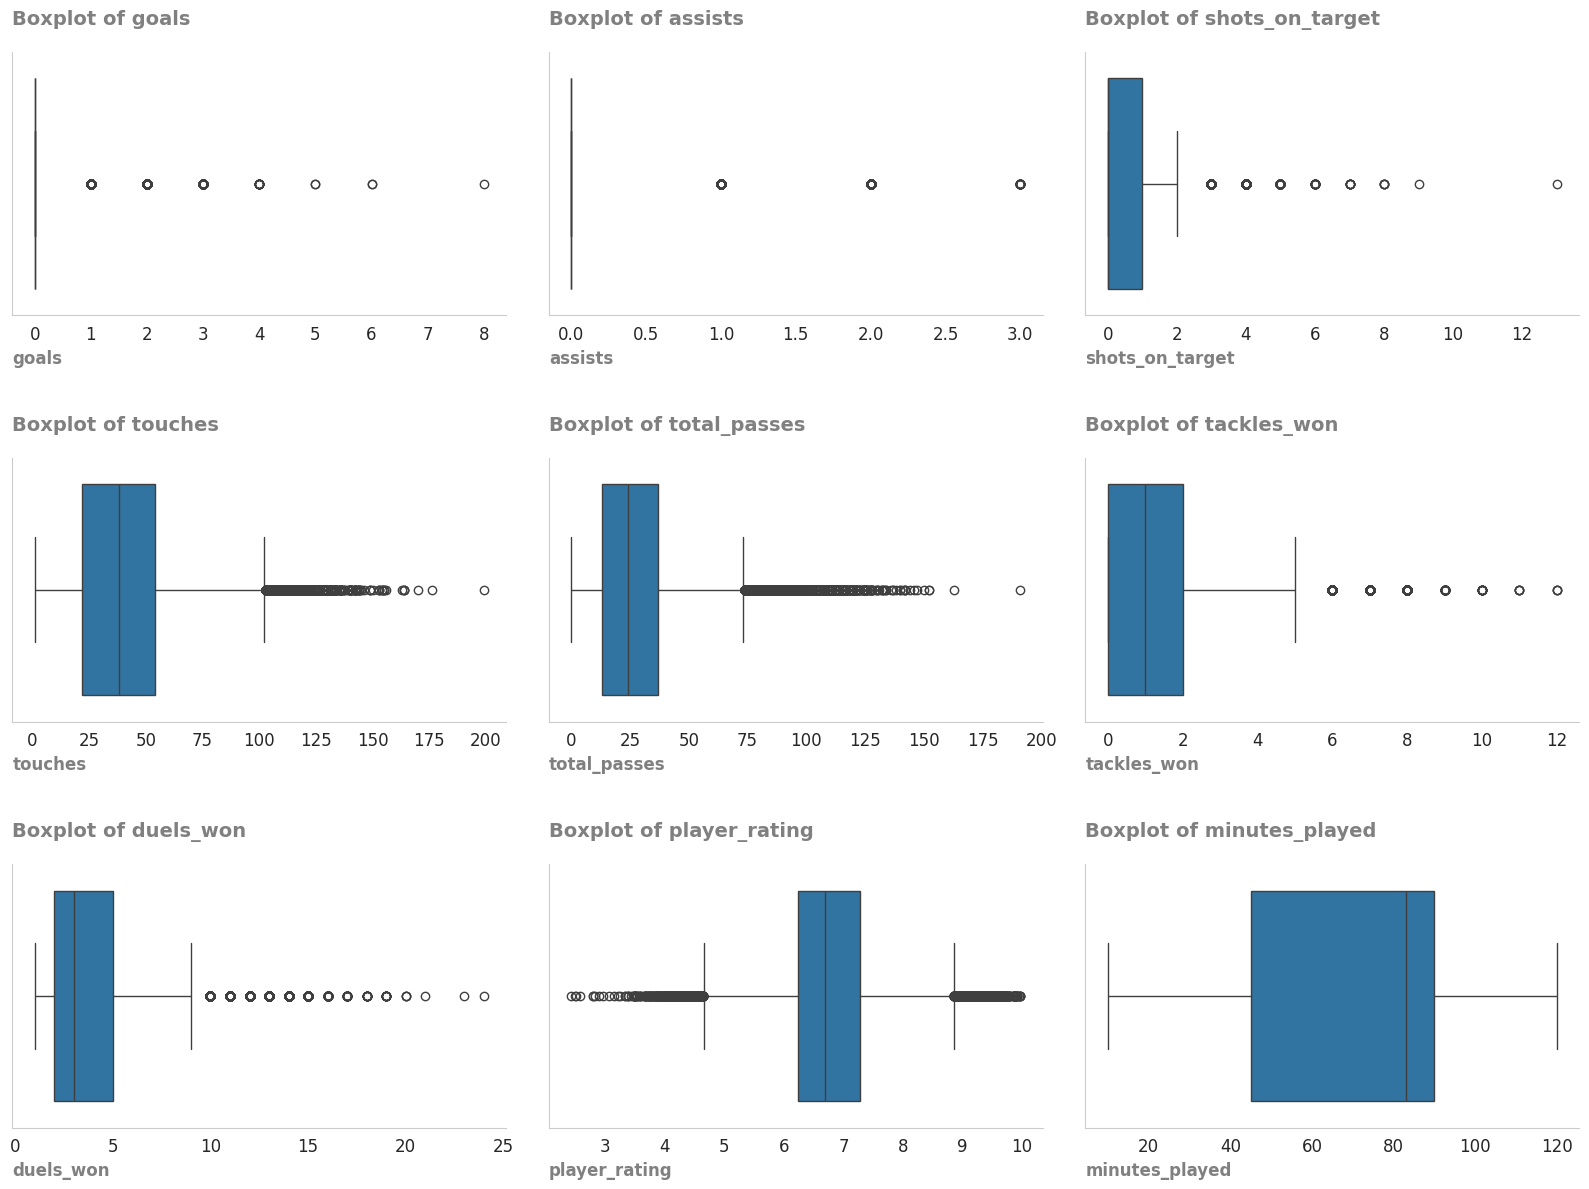

In [15]:
key_cols = [
    'goals', 'assists', 'shots_on_target',
    'touches', 'total_passes', 'tackles_won',
    'duels_won', 'player_rating', 'minutes_played'
]


plt.figure(figsize=(16, 12))
for i, col in enumerate(key_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}" , loc= "left", weight= "bold" ,color= "gray", fontsize= 14, pad=20)
    plt.xlabel(col, weight= "bold",loc= "left", color= "gray", fontsize= 12)
    ax = plt.gca()

    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.tick_params(axis="x", color= "gray", labelsize= "large")
    ax.tick_params(axis="y", color= "gray", labelsize= "large")
    ax.grid(False)
    

plt.tight_layout(h_pad=3.5, w_pad=2.0)
plt.show()


#### 2.1.2 Identifying outliers with the IQR method

In [16]:
def iqr_outlier_summary(data, cols):
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((data[c] < lower) | (data[c] > upper)).sum()
        rows.append([c, lower, upper, n_out, n_out / len(data) * 100])
    return pd.DataFrame(rows, columns=['column', 'lower_bound', 'upper_bound',
                                        'n_outliers', 'pct_outliers']).sort_values('pct_outliers', ascending=False)


iqr_summary = iqr_outlier_summary(df, [c for c in stat_cols if c != 'stat_recorded'])
iqr_summary


,column,lower_bound,upper_bound,n_outliers,pct_outliers
40,aerial_duels_won,-1.500000,2.500000,20258,11.897365
0,home_score,-0.500000,3.500000,13862,8.141044
31,clearances,-3.000000,5.000000,12953,7.607196
7,goals,0.000000,0.000000,12912,7.583117
27,long_ball_attempts,-5.000000,11.000000,12048,7.075696
26,accurate_long_balls,-3.000000,5.000000,11987,7.039871
43,fouls_committed,-1.500000,2.500000,11837,6.951777
44,was_fouled,-1.500000,2.500000,11686,6.863096
8,assists,0.000000,0.000000,9376,5.506451
17,dribble_attempts,-0.500000,3.500000,9348,5.490007


**Result** 

Due to the statistical nature of football data (most values are 0 or small, with a few high values for
exceptional performances), the IQR method incorrectly flags a large percentage of the data as "outliers"
(e.g. `goals`: 7.5%). These are **natural outliers**, not data errors.

we now look for **genuine logical errors**.


#### 2.1.3 Checking logical/physical data errors (these are not "natural" outliers, they are recording errors)

In [17]:
# 'player_rating': should be between 0 and 10

print("=== player_rating ===")
print(df['player_rating'].describe())
print("Outside [0,10]:", ((df['player_rating'] < 0) | (df['player_rating'] > 10)).sum())


=== player_rating ===
count    170273.000000
mean          6.780236
std           0.750544
min           2.430000
25%           6.240000
50%           6.690000
75%           7.280000
max           9.920000
Name: player_rating, dtype: float64
Outside [0,10]: 0


In [18]:
# `minutes_played`: should be between 0 and roughly 120 (90 minutes + stoppage time)

print()
print("=== minutes_played ===")
print(df['minutes_played'].describe())
print("Negative:", (df['minutes_played'] < 0).sum())
print("Above 120:", (df['minutes_played'] > 120).sum())


=== minutes_played ===
count    170273.000000
mean         67.881749
std          27.494836
min          10.000000
25%          45.000000
50%          83.000000
75%          90.000000
max         120.000000
Name: minutes_played, dtype: float64
Negative: 0
Above 120: 0


In [19]:
# Percentage columns (`*_accuracy`, `*_success_rate`): should be between 0 and 100

true_pct_cols = ['pass_accuracy', 'dribble_success_rate', 'cross_success_rate',
                  'long_ball_success_rate', 'ground_duel_success_rate', 'aerial_duel_success_rate']

for c in true_pct_cols:
    bad = ((df[c] < 0) | (df[c] > 100)).sum()
    print(f"{c}: {bad} value(s) outside [0,100]")


pass_accuracy: 0 value(s) outside [0,100]
dribble_success_rate: 0 value(s) outside [0,100]
cross_success_rate: 0 value(s) outside [0,100]
long_ball_success_rate: 0 value(s) outside [0,100]
ground_duel_success_rate: 0 value(s) outside [0,100]
aerial_duel_success_rate: 0 value(s) outside [0,100]


In [20]:
# Count columns (`goals`, `assists`, ...): should not be negative

count_cols = [c for c in stat_cols if c not in true_pct_cols + ['goal_difference', 'player_rating', 'stat_recorded']]

neg_found = False
for c in count_cols:
    n_neg = (df[c] < 0).sum()
    if n_neg > 0:
        print(f"{c}: {n_neg} negative value(s)!")
        neg_found = True
if not neg_found:
    print("No negative values found in the count columns")


No negative values found in the count columns


In [21]:
# Where the "successful/accurate" value exceeds the "total attempts" value (which is physically impossible)

consistency_pairs = [
    ('accurate_passes', 'total_passes'),
    ('accurate_crosses', 'cross_attempts'),
    ('accurate_long_balls', 'long_ball_attempts'),
    ('successful_dribbles', 'dribble_attempts'),
    ('ground_duels_won', 'ground_duel_attempts'),
    ('aerial_duels_won', 'aerial_duel_attempts'),
]

print("Checking cases (successful > attempts):")
for success_col, attempt_col in consistency_pairs:
    violations = (df[success_col] > df[attempt_col]).sum()
    print(f"  {success_col} > {attempt_col}: {violations} case")


Checking cases (successful > attempts):
  accurate_passes > total_passes: 0 case
  accurate_crosses > cross_attempts: 0 case
  accurate_long_balls > long_ball_attempts: 0 case
  successful_dribbles > dribble_attempts: 0 case
  ground_duels_won > ground_duel_attempts: 0 case
  aerial_duels_won > aerial_duel_attempts: 0 case


**Result:** 

no genuine data errors were found. The "outlier" values flagged by the statistical IQR method
(such as 9-0 score lines or a player scoring 4 goals in a match) are all natural, real football events, not
recording errors.


### 3.1 Checking for duplicate records

In [22]:
full_dupes = df.duplicated().sum()

print(f"Number of fully duplicated rows: {full_dupes}")


Number of fully duplicated rows: 0


In [23]:
key_dupes = df.duplicated(subset=['match_id', 'player_id']).sum()

print(f"Number of duplicate records based on (match_id, player_id): {key_dupes}")


Number of duplicate records based on (match_id, player_id): 0


**Result**

Both checks return zero duplicates: no fully duplicated rows and no repeated `(match_id, player_id)` combinations. This confirms the dataset is structurally clean at the record level, so no rows need to be removed at this stage.

### 4.1 Column review

In [24]:
# Number of unique values per column - to find near-constant columns
nunique_summary = df.nunique().sort_values()

nunique_summary


parent_league_season        1
is_home_team                2
is_goalkeeper               2
stat_recorded               2
team_result                 3
                        ...  
team_id                  1309
team_name                1319
match_id                 6673
player_name             27082
player_id               27264
Length: 64, dtype: int64

In [25]:
# Redundancy check: can home_score/away_score be fully derived from team_goals + opponent_goals + is_home_team?

check = df.copy()

check['derived_team_goals'] = np.where(check['is_home_team'] == 1, check['home_score'], check['away_score'])
check['derived_opponent_goals'] = np.where(check['is_home_team'] == 1, check['away_score'], check['home_score'])

match_team = (check['derived_team_goals'] == check['team_goals']).mean() * 100
match_opp = (check['derived_opponent_goals'] == check['opponent_goals']).mean() * 100

print(f"Match rate of team_goals with the value derived from home/away_score: {match_team:.2f}%")
print(f"Match rate of opponent_goals with the value derived from home/away_score: {match_opp:.2f}%")


Match rate of team_goals with the value derived from home/away_score: 100.00%
Match rate of opponent_goals with the value derived from home/away_score: 100.00%


**Conclusion and column-drop decision:**

Based on the checks above (`nunique` and the redundancy check), the following columns are proposed for removal:

| Column | Reason for removal |
|---|---|
| `home_score`, `away_score` | Fully derivable from `team_goals` + `opponent_goals` + `is_home_team` (redundant) |
| `home_team_id`, `away_team_id` | The team name (`home_team_name`, `away_team_name`) is available and sufficient for analysis/dashboard |
| `parent_league_name`, `parent_league_season` | Low-value contextual information for this project's EDA/modeling goals |

ID columns such as `match_id`, `player_id`, `team_id`, `league_id` are kept because they're needed for EDA
(grouping) and for connecting with Power BI, even if they aren't directly used in the machine-learning model
(they'll be dropped separately during the modeling stage).


In [26]:
cols_to_drop = ['home_score', 'away_score', 'home_team_id', 'away_team_id',
                'parent_league_name', 'parent_league_season']

df = df.drop(columns=cols_to_drop)

print(f"Dropped columns: {cols_to_drop}")
print(f"Remaining number of columns: {df.shape[1]}")

df.info()


Dropped columns: ['home_score', 'away_score', 'home_team_id', 'away_team_id', 'parent_league_name', 'parent_league_season']
Remaining number of columns: 58
<class 'pandas.DataFrame'>
Index: 170273 entries, 0 to 173586
Data columns (total 58 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   match_id                  170273 non-null  int64  
 1   match_date                170273 non-null  str    
 2   league_id                 170273 non-null  int64  
 3   league_name               170273 non-null  str    
 4   country_code              170273 non-null  str    
 5   home_team_name            170273 non-null  str    
 6   away_team_name            170273 non-null  str    
 7   is_home_team              170273 non-null  int64  
 8   team_goals                170273 non-null  float64
 9   opponent_goals            170273 non-null  float64
 10  goal_difference           170273 non-null  float64
 11  team_result     

### 5.1 Final cleaning-phase summary

| Stage | Result |
|---|---|
| Missing Values | 3,314 rows dropped (1.91%), 19 columns filled with 0, 2 columns (`expected_assists`, `xg_plus_xa`) excluded from modeling, `stat_recorded` flag created |
| Outliers | No genuine errors found; no rows removed |
| Duplicates | Zero duplicate records |
| Column Review | 6 redundant columns removed |

**Result:** 

from an initial 173,587 rows and 63 columns, we arrive at a clean **170,273 rows and 58 columns**.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Target variable analysis (`player_rating`)

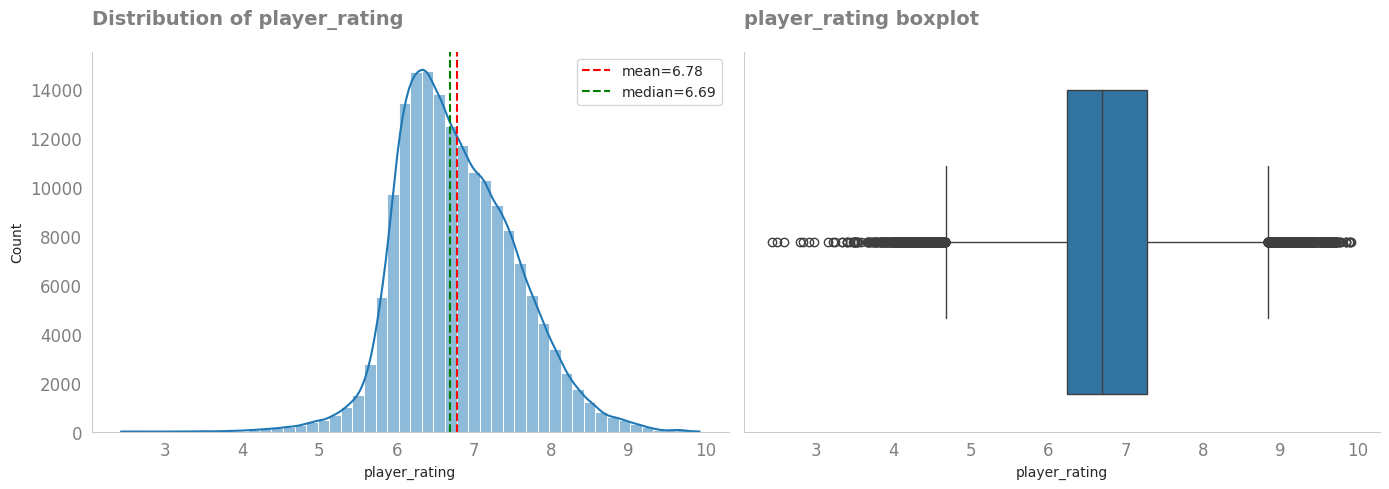

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['player_rating'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of player_rating',loc= "left", weight= "bold" ,color= "gray", fontsize= 14, pad=20)
axes[0].axvline(df['player_rating'].mean(), color='red', linestyle='--', label=f"mean={df['player_rating'].mean():.2f}")
axes[0].axvline(df['player_rating'].median(), color='green', linestyle='--', label=f"median={df['player_rating'].median():.2f}")
axes[0].legend()
axes[0].spines["right"].set_visible(False)
axes[0].spines["top"].set_visible(False)
axes[0].tick_params(axis="x", colors="gray", labelsize= "large")
axes[0].tick_params(axis="y", colors= "gray", labelsize= "large")
axes[0].grid(False)


sns.boxplot(x=df['player_rating'], ax=axes[1])
axes[1].set_title('player_rating boxplot',loc= "left", weight= "bold" ,color= "gray", fontsize= 14, pad=20)
axes[1].spines["right"].set_visible(False)
axes[1].spines["top"].set_visible(False)
axes[1].tick_params(axis="x", colors= "gray", labelsize= "large")
axes[1].tick_params(axis="y", colors= "gray", labelsize= "large")
axes[1].grid(False)

plt.tight_layout()
plt.show()


In [28]:
print(df['player_rating'].describe())
print(f"Skewness: {df['player_rating'].skew():.3f}")


count    170273.000000
mean          6.780236
std           0.750544
min           2.430000
25%           6.240000
50%           6.690000
75%           7.280000
max           9.920000
Name: player_rating, dtype: float64
Skewness: 0.335


**Result:** 

Mean = 6.78, median = 6.69, and skewness is low (0.335). Therefore, the distribution is approximately normal with a slight right skew, indicating that a small number of exceptionally high-performing players have pulled the distribution slightly to the right.

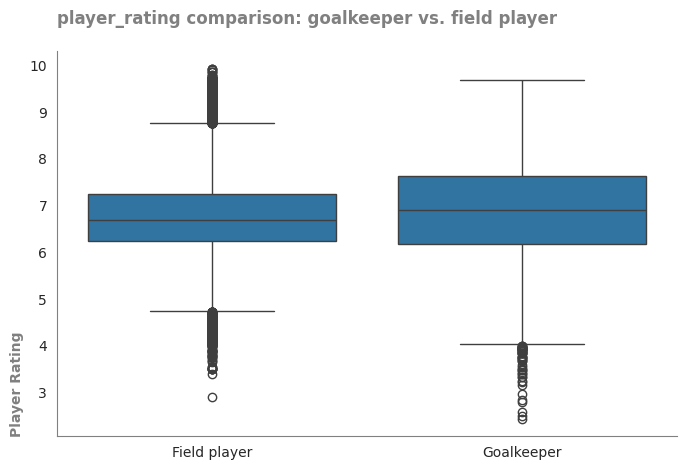

In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='is_goalkeeper', y='player_rating')

plt.xticks([0, 1], ['Field player', 'Goalkeeper'])

plt.title('player_rating comparison: goalkeeper vs. field player',loc="left", weight="bold", color="gray", fontsize=12, pad=20)

ax = plt.gca()

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_xlabel("")
ax.set_ylabel("Player Rating", loc= "bottom", weight="bold", color="gray", fontsize=10)

plt.grid(False)
plt.show()


In [30]:
print(df.groupby('is_goalkeeper')['player_rating'].describe())

                  count      mean       std   min   25%   50%   75%   max
is_goalkeeper                                                            
0              157383.0  6.773810  0.724769  2.90  6.24  6.68  7.25  9.92
1               12890.0  6.858692  1.010449  2.43  6.17  6.89  7.62  9.68


**Result**: 

Goalkeepers have a slightly higher average rating (6.86 vs. 6.77), but their standard deviation is much larger (1.01 vs. 0.72). This makes sense because goalkeeper performance is often more “binary”: they may make an outstanding save and receive a very high rating, or make a costly mistake and receive a very low rating. In contrast, outfield players tend to have more balanced and consistently distributed performances.

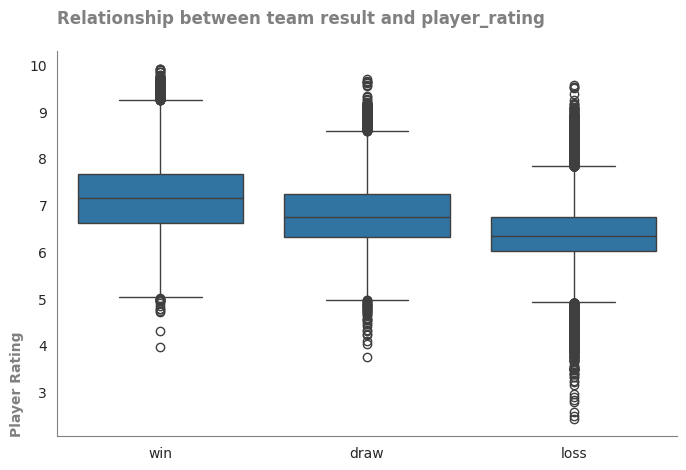

In [31]:
plt.figure(figsize=(8, 5))
order = ['win', 'draw', 'loss']
sns.boxplot(data=df, x='team_result', y='player_rating', order=order)

plt.title('Relationship between team result and player_rating',loc="left", weight="bold", color="gray", fontsize=12, pad=20)

ax = plt.gca()

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_xlabel("")
ax.set_ylabel("Player Rating", loc= "bottom", weight="bold", color="gray", fontsize=10)

plt.grid(False)

plt.show()


In [32]:
print(df.groupby('team_result')['player_rating'].mean().reindex(order))

team_result
win     7.178698
draw    6.808220
loss    6.382942
Name: player_rating, dtype: float64


**Result:** 

players whose team won usually get a higher rating 

### 2.2 Contextual analysis (leagues, home/away)

In [33]:
# Average rating by league (leagues with at least 500 records, for statistical validity)

league_rating = df.groupby('league_name').agg(
    n_records=('player_rating', 'count'),
    avg_rating=('player_rating', 'mean')
).query('n_records >= 500').sort_values('avg_rating', ascending=False)

print("Top 10 Leagues with the Highest Average Player Ratings:")
display(league_rating.head(10))

print("\n‌Top 10 Leagues with the Lowest Average Player Ratings:")
display(league_rating.tail(10))


Top 10 Leagues with the Highest Average Player Ratings:


,n_records,avg_rating
league_name,,
Bundesliga Championship Group,622,6.886672
Saudi Pro League,2639,6.871830
Allsvenskan,2261,6.853092
Veikkausliiga,1383,6.852299
Europa League Final Stage,717,6.845342
A-League Women,899,6.845050
Eliteserien,1677,6.841646
1. Division Relegation Group,810,6.839531
Superligaen Championship Playoff,642,6.835202



‌Top 10 Leagues with the Lowest Average Player Ratings:


,n_records,avg_rating
league_name,,
Premier League Championship Group,826,6.748366
WSL,1095,6.745324
HNL,1533,6.739876
USL Championship,3142,6.735404
Frauen-Bundesliga,1107,6.729530
Liga F,2278,6.727256
Premier League Relegation Group,824,6.720850
Thai League,1543,6.704238
K-League 2,2277,6.697101


**Result** 

The difference between the league with the highest average rating (6.89) and the one with the lowest average rating (6.67) is only about 0.22 points. This suggests that the league alone does not have a strong effect on player ratings.

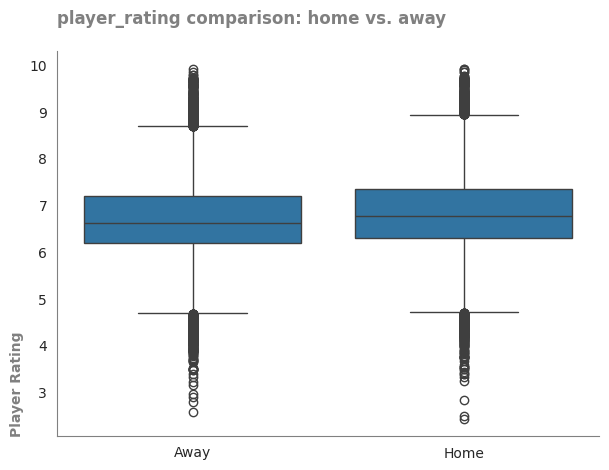

In [34]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='is_home_team', y='player_rating')
plt.xticks([0, 1], ['Away', 'Home'])

plt.title('player_rating comparison: home vs. away',loc="left", weight="bold", color="gray", fontsize=12, pad=20)
ax = plt.gca()

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_xlabel("")
ax.set_ylabel("Player Rating", loc= "bottom", weight="bold", color="gray", fontsize=10)

plt.grid(False)

plt.show()


In [35]:
print(df.groupby('is_home_team')['player_rating'].mean())

is_home_team
0    6.711767
1    6.849956
Name: player_rating, dtype: float64


**Result** 

Home teams have a higher average rating (6.85 vs. 6.71), indicating a home-field advantage. This well-known pattern in real-world football is also reflected in the dataset.

### 2.3 Correlation of variables with `player_rating`

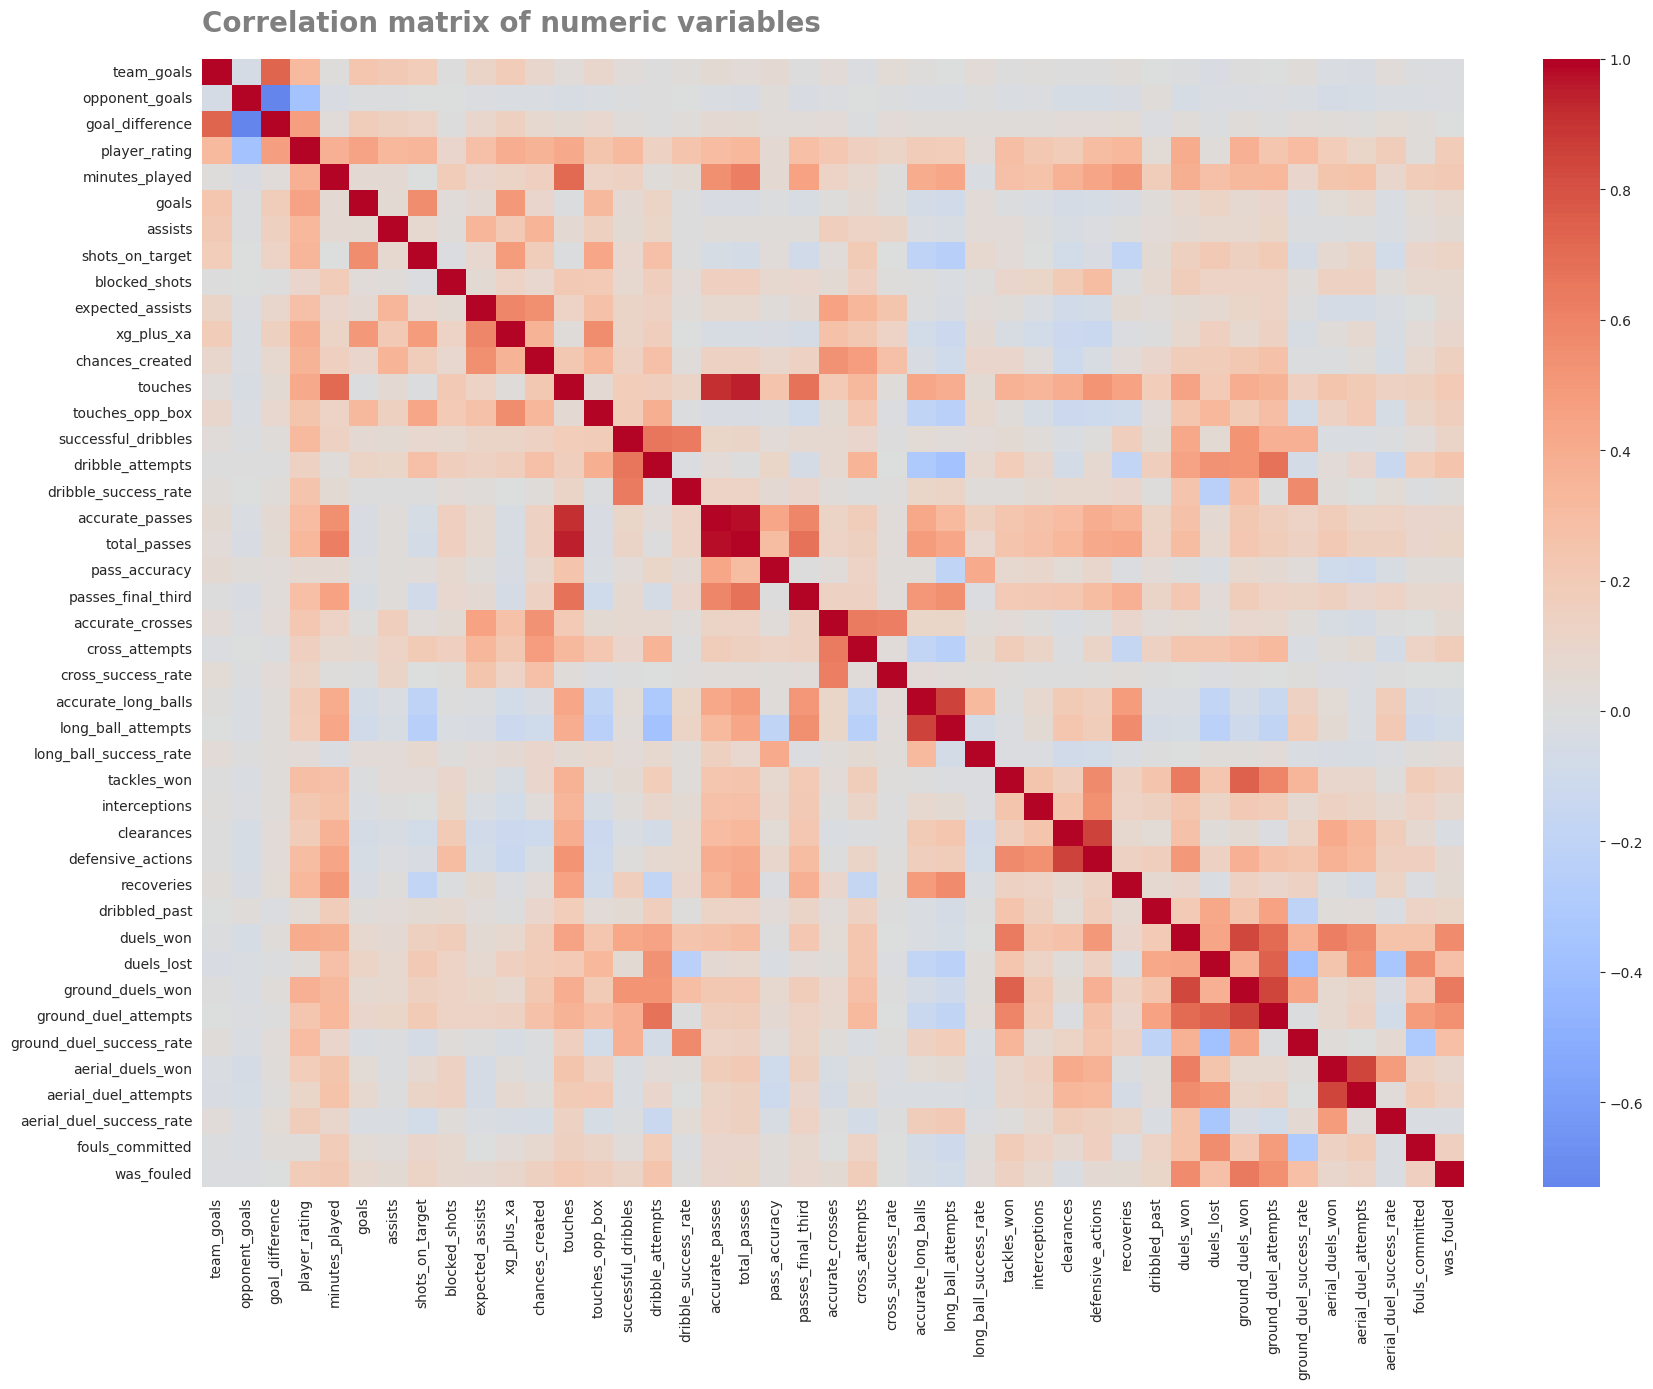

In [36]:
exclude_from_corr = ['match_id', 'league_id', 'player_id', 'team_id', 'is_home_team',
                      'is_goalkeeper', 'stat_recorded']
numeric_for_corr = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude_from_corr]

corr_matrix = df[numeric_for_corr].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix of numeric variables',loc="left", weight="bold", color="gray", fontsize=20, pad=20)
plt.tight_layout()
plt.show()


In [37]:
rating_corr = corr_matrix['player_rating'].drop('player_rating').sort_values(ascending=False)

print("Top 10 variables with the highest positive correlation with player_rating:")
print(rating_corr.head(10))

print("\nTop 10 variables with the lowest (most negative) correlation with player_rating:")
print(rating_corr.tail(10))


Top 10 variables with the highest positive correlation with player_rating:
goal_difference     0.470984
goals               0.447546
touches             0.412867
duels_won           0.401236
xg_plus_xa          0.395051
minutes_played      0.383142
ground_duels_won    0.379591
chances_created     0.361870
shots_on_target     0.349797
total_passes        0.335776
Name: player_rating, dtype: float64

Top 10 variables with the lowest (most negative) correlation with player_rating:
dribble_attempts          0.140112
cross_success_rate        0.116929
aerial_duel_attempts      0.105864
blocked_shots             0.098524
pass_accuracy             0.058105
dribbled_past             0.046808
long_ball_success_rate    0.040334
fouls_committed           0.020182
duels_lost                0.015118
opponent_goals           -0.367423
Name: player_rating, dtype: float64


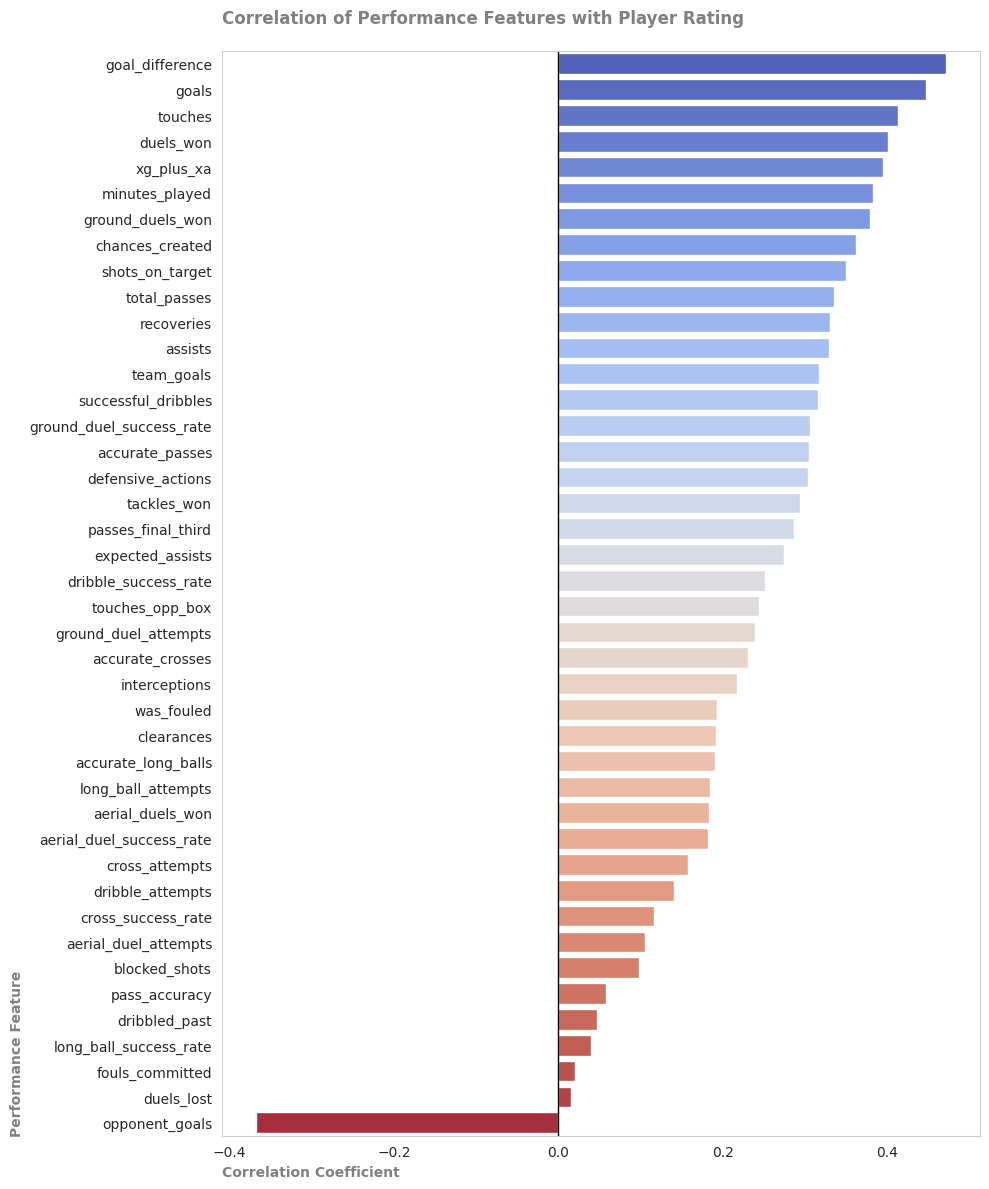

In [38]:
plt.figure(figsize=(10, 12))

sns.barplot(
    x=rating_corr.values,
    y=rating_corr.index,
    palette="coolwarm" ,
    hue=rating_corr.index,
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Correlation of Performance Features with Player Rating",loc="left", weight="bold", color="gray", fontsize=12, pad=20)
plt.xlabel("Correlation Coefficient", loc= "left", weight="bold", color="gray", fontsize=10)
plt.ylabel("Performance Feature", loc= "bottom", weight="bold", color="gray", fontsize=10)

plt.grid(False)
plt.tight_layout()
plt.show()



**Result** 

Almost no individual statistic has a strong negative relationship with player rating, except for team-related outcomes such as goals conceded. One possible explanation is that even “negative” actions—such as being dribbled past or committing fouls—often occur more frequently for highly involved players who have more touches and participate more actively in the game. As a result, the negative effect of these actions may be offset by the positive effect of high overall involvement.

### 2.4 Top players

In [39]:
# For a fair comparison, only players with a reasonable minimum number of matches (e.g. ≥ 10) are considered.

player_agg = df.groupby('player_name').agg(
    matches_played=('match_id', 'nunique'),
    avg_rating=('player_rating', 'mean'),
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum'),
).reset_index()

eligible_players = player_agg[player_agg['matches_played'] >= 10]

print("Top 10 players by average player_rating (minimum 10 matches):")

display(eligible_players.sort_values('avg_rating', ascending=False).head(10))


Top 10 players by average player_rating (minimum 10 matches):


,player_name,matches_played,avg_rating,total_goals,total_assists
16840,Mariona Caldentey,10,8.311000,7.0,1.0
6931,Emam Ashour,10,8.100000,5.0,3.0
4926,Cristian Guanca,12,8.065000,8.0,5.0
4699,Claudia Pina,13,8.062308,13.0,5.0
22644,Salem Al-Dawsari,11,8.049091,7.0,5.0
1305,Alexandra Chidiac,11,8.031818,1.0,3.0
18878,Mourad Batna,10,8.009000,5.0,5.0
4002,Carles Gil,10,8.007000,4.0,2.0
22584,Sadio Mané,12,7.990000,9.0,5.0
15233,Lionel Messi,14,7.985714,10.0,3.0


In [40]:
print("Top 10 players by total goals scored:")
display(eligible_players.sort_values('total_goals', ascending=False).head(10))


Top 10 players by total goals scored:


,player_name,matches_played,avg_rating,total_goals,total_assists
14556,Kylian Mbappé,15,7.826000,13.0,2.0
4699,Claudia Pina,13,8.062308,13.0,5.0
3596,Brian White,19,6.900526,11.0,0.0
7476,Ewa Pajor,12,7.764167,11.0,4.0
9536,Harry Kane,14,7.728571,10.0,2.0
4978,Cristiano Ronaldo,10,7.771000,10.0,0.0
9879,Hugo Cuypers,12,7.820000,10.0,0.0
15233,Lionel Messi,14,7.985714,10.0,3.0
26696,Yu Tsukanome,11,7.544545,10.0,0.0
25611,Vangelis Pavlidis,13,7.523077,10.0,2.0


In [41]:
print("Top 10 players by total assists:")
display(eligible_players.sort_values('total_assists', ascending=False).head(10))


Top 10 players by total assists:


,player_name,matches_played,avg_rating,total_goals,total_assists
15555,Lucas Fernandes,17,7.351176,3.0,8.0
18064,Michael Olise,13,7.867692,4.0,7.0
18288,Mikey Maldonado,11,7.357273,1.0,7.0
26748,Yunus Akgün,11,7.606364,1.0,7.0
11708,Jhon Arias,16,7.532500,1.0,7.0
18800,Morgan Rogers,16,7.181250,2.0,7.0
5582,David Da Costa,14,7.493571,1.0,6.0
15850,Luis Suárez,21,7.324762,8.0,6.0
17343,Mathias Jørgensen,22,6.900000,3.0,6.0
2758,Awer Mabil,12,7.193333,0.0,6.0


**Result:**

Three different rankings(average rating, total goals, total assists) surface well-known, recognizable players — such as Messi, Mbappé, Cristiano Ronaldo, and Sadio Mané — which serves as an informal sanity check confirming the dataset's quality and realism. Notably, the "assists" list has zero overlap with the other two rankings, while the "rating" and "goals" lists share two names (Lionel Messi, Claudia Pina). This shows that scoring alone doesn't guarantee the highest rating — most top-rated players (e.g. Mariona Caldentey, Salem Al-Dawsari) are not among the top scorers — but a small overlap does exist for elite two-way contributors, indicating `player_rating` captures more than just goal output.

## 3. Modeling: predicting `player_rating`

### 3.1 Feature selection

Based on previous analysis, the following columns are excluded from the model:

| Category | Columns | Reason for exclusion |
|---|---|---|
| IDs and names | `match_id`, `player_id`, `team_id`, `league_id`, `player_name`, `team_name`, `home_team_name`, `away_team_name` | No predictive meaning |
| Raw date | `match_date` | Replaced with an extracted `match_month` |
| League-dependent quality | `expected_assists`, `xg_plus_xa` | Strong dependency on data-recording quality per league (per previous analysis) |
| Derived percentage rates | `dribble_success_rate`, `cross_success_rate`, `long_ball_success_rate`, `ground_duel_success_rate`, `aerial_duel_success_rate`, `pass_accuracy` | Redundant information relative to the raw columns (won/attempts) |
| Weak-effect contextual | `league_name`, `country_code` | Weak effect per EDA (0.22 gap between the highest/lowest league) and high cardinality |


In [42]:
model_df = df.copy()

model_df['match_date'] = pd.to_datetime(
    model_df['match_date'],
    errors='coerce'
)
model_df['match_month'] = model_df['match_date'].dt.month

drop_cols = [
    'match_id', 'player_id', 'team_id', 'league_id',
    'player_name', 'team_name', 'home_team_name', 'away_team_name',
    'match_date',
    'expected_assists', 'xg_plus_xa',
    'dribble_success_rate', 'cross_success_rate', 'long_ball_success_rate',
    'ground_duel_success_rate', 'aerial_duel_success_rate', 'pass_accuracy',
    'league_name', 'country_code',
]

target = 'player_rating'
feature_cols = [c for c in model_df.columns if c not in drop_cols + [target]]

model_data = pd.get_dummies(model_df[feature_cols + [target]], columns=['team_result'], drop_first=True)


### 3.2 Train/Test split

In [43]:
X = model_data.drop(columns=[target])
y = model_data[target]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (136218, 40) | Test: (34055, 40)


### 3.3 Model Linear Regression

In [44]:
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_imp, y_train)

y_train_pred_lr = lr_model.predict(X_train_imp)
y_test_pred_lr = lr_model.predict(X_test_imp)

def evaluate(y_true, y_pred, label):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{label} -> RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")
    return rmse, mae, r2

print("=== Linear Regression ===")
evaluate(y_train, y_train_pred_lr, "Train")
evaluate(y_test, y_test_pred_lr, "Test ")

=== Linear Regression ===
Train -> RMSE: 0.3518 | MAE: 0.2404 | R2: 0.7811
Test  -> RMSE: 0.3482 | MAE: 0.2380 | R2: 0.7818


(0.34820861097099814, 0.23799138876387738, 0.7818364291731679)

**Result:** 

The linear regression baseline achieves a Test R2 of 0.7818, meaning it explains about 78% of the variance in `player_rating`. The Train and Test scores are nearly identical (0.7811 vs 0.7818), showing no
overfitting.

### 3.4 Model Random Forest

In [45]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42,n_jobs=-1)

rf_model.fit(X_train , y_train)

y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

print("=== RandomForestRegressor ===")
evaluate(y_train, y_train_pred_rf, "Train")
evaluate(y_test, y_test_pred_rf, "Test ")

=== RandomForestRegressor ===
Train -> RMSE: 0.2228 | MAE: 0.1526 | R2: 0.9121
Test  -> RMSE: 0.2926 | MAE: 0.1968 | R2: 0.8460


(0.292582463908279, 0.1967530329331768, 0.8459719541074471)

**Result**

The Random Forest model shows a train/test gap (Train R2=0.9121 vs Test R2=0.8460, a gap of ~0.066), indicating mild overfitting.

### 3.5 Model XGBoost

In [46]:
xgb_model = XGBRegressor(n_estimators=150, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1)

xgb_model.fit(X_train, y_train)

y_train_pred_xgb = xgb_model.predict(X_train)
y_test_pred_xgb = xgb_model.predict(X_test)

print("=== XGBoost Regressor ===")
evaluate(y_train, y_train_pred_xgb, "Train")
evaluate(y_test, y_test_pred_xgb, "Test ")

=== XGBoost Regressor ===
Train -> RMSE: 0.2533 | MAE: 0.1597 | R2: 0.8865
Test  -> RMSE: 0.2651 | MAE: 0.1665 | R2: 0.8736


(0.2650898740399331, 0.1665185050351069, 0.8735585413000256)

**Result:** 

The XGBoost model achieves the best performance with a Test R2 of 0.8736, explaining over 87% of the variance in player_rating. The close alignment between Train and Test scores (0.8865 vs. 0.8736) confirms excellent generalization capabilities without overfitting.

### 3.6 Model comparison summary

In [47]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'RandomForestRegressor' , 'XGBRegressor'],
    'Test_RMSE': [
        mean_squared_error(y_test, y_test_pred_lr) ** 0.5,
        mean_squared_error(y_test, y_test_pred_rf) ** 0.5,
        mean_squared_error(y_test, y_test_pred_xgb) ** 0.5,
        
    ],
    'Test_MAE': [
        mean_absolute_error(y_test, y_test_pred_lr),
        mean_absolute_error(y_test, y_test_pred_rf),
        mean_absolute_error(y_test, y_test_pred_xgb)
    ],
    'Test_R2': [
        r2_score(y_test, y_test_pred_lr),
        r2_score(y_test, y_test_pred_rf),
        r2_score(y_test, y_test_pred_xgb)
    ]
})
results


,Model,Test_RMSE,Test_MAE,Test_R2
0,Linear Regression,0.348209,0.237991,0.781836
1,RandomForestRegressor,0.292582,0.196753,0.845972
2,XGBRegressor,0.265090,0.166519,0.873559


**Observations**

**Rising accuracy trend (R2):**

The R2 value increased from the baseline linear model (78.18%) to Random Forest (84.59%), and finally to Extreme Gradient Boosting (87.35%). The XGBoost model was able to explain more than 87% of the variance in player ratings.

**Declining Mean Absolute Error (MAE):**

The average prediction error in the final model reached 0.1665 points. This means XGBoost's predictions are, on average, only about 0.17 points away from the player's actual rating.

**Reduction in large errors (RMSE):**

RMSE, which is more sensitive to large errors and outliers, dropped from 0.3482 in linear regression to 0.2650 in XGBoost (about a 23.6% improvement in penalizing large errors).

**Final model selection:** the XGBRegressor model is selected as the project's final, champion model.

### 3.7 Feature importance

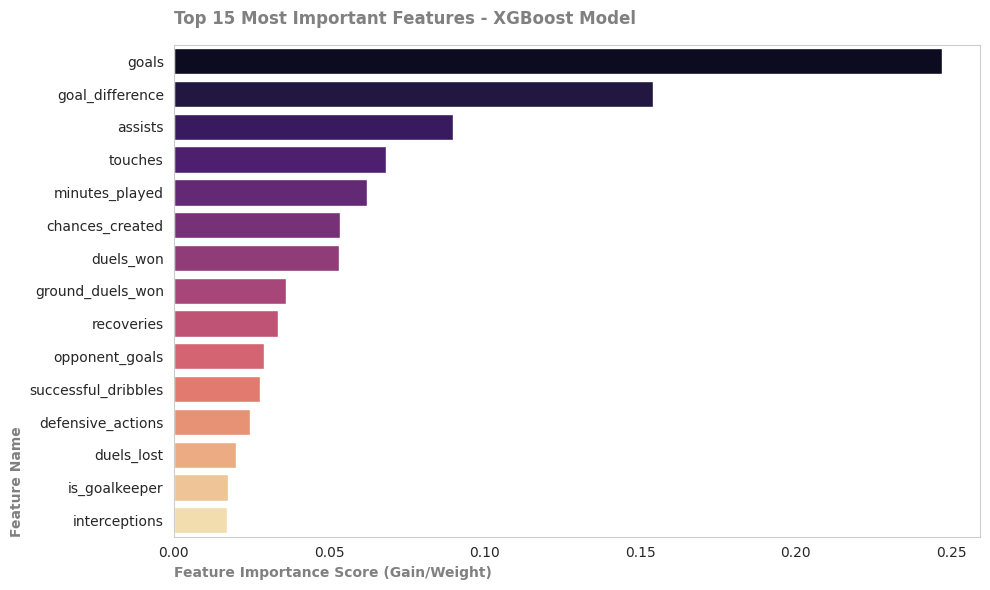

In [48]:
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', hue='Feature', palette='magma', legend=False)

plt.title('Top 15 Most Important Features - XGBoost Model', fontsize=12, pad=15,loc="left", weight="bold", color="gray")


plt.xlabel('Feature Importance Score (Gain/Weight)', fontsize=10, loc= "left", weight="bold", color="gray")
plt.ylabel('Feature Name', fontsize=10,loc= "bottom", weight="bold", color="gray" )

plt.tight_layout()
plt.grid(False)
plt.show()


In [49]:
print("=== Top 10 Most Important Features ===")
print(importance_df.head(10).to_string(index=False))

=== Top 10 Most Important Features ===
         Feature  Importance
           goals    0.246917
 goal_difference    0.154239
         assists    0.089720
         touches    0.068189
  minutes_played    0.062295
 chances_created    0.053575
       duels_won    0.053271
ground_duels_won    0.036271
      recoveries    0.033578
  opponent_goals    0.028971


**Observations**

**Decisive Offensive Contribution:**

`goals` (24.7%) and `assists` (8.9%) together make up about one-third of the model's total scoring weight. Scoring a goal produces the largest positive jump in a player's final rating. `chances_created` (5.4%) adds further weight to this category, showing that even creating scoring opportunities without directly scoring or assisting still meaningfully boosts a player's rating.

**Contextual Match Outcome:**

`goal_difference` (15.4%) and `opponent_goals` (3.0%) show that a player's individual performance is not separate from the team's overall performance; players in high-scoring wins receive noticeably higher ratings.

**Involvement & Volume:**

`touches` (6.8%) and `minutes_played` (6.2%) show that simply being on the pitch and staying involved in play is a key factor in avoiding a rating drop.

**Defensive / Physical Duels:**

The combined weight of `duels_won` (5.3%), `recoveries` (3.4%), and `ground_duels_won` (3.6%) proves that, besides forwards, the model also heavily weights the fighting performance of midfielders and defenders.

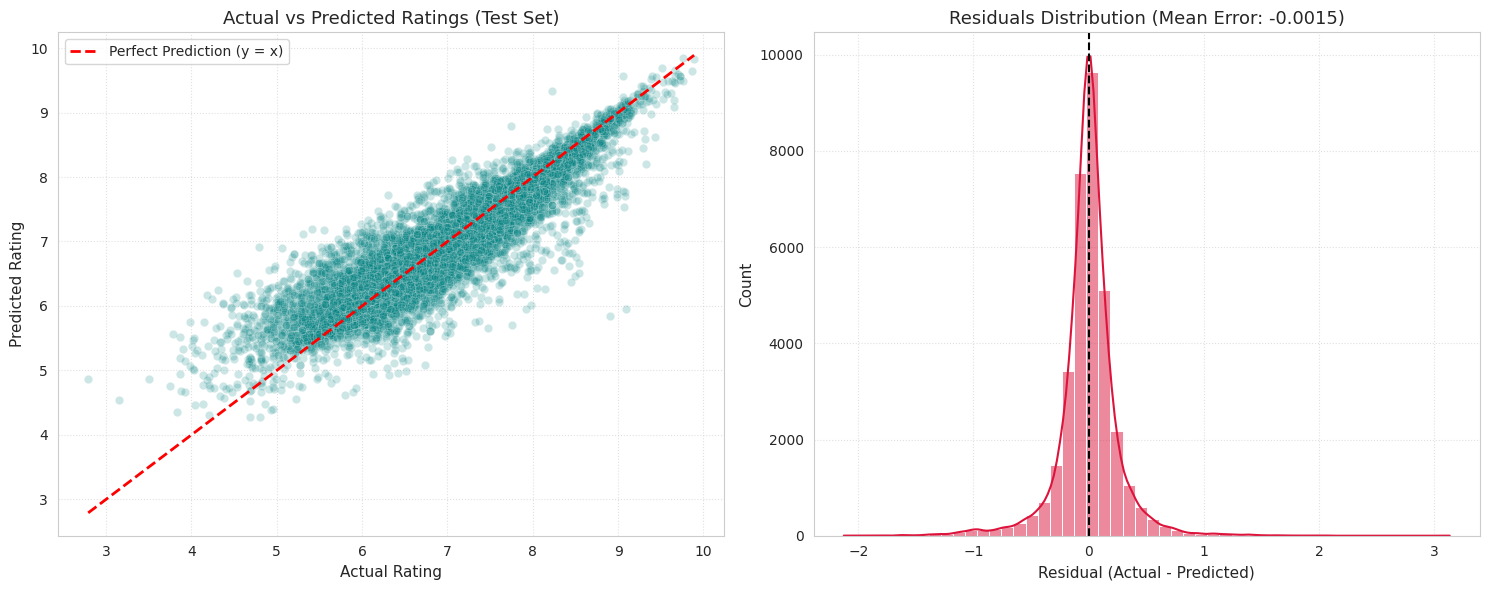

In [50]:
residuals = y_test - y_test_pred_xgb

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    x=y_test, 
    y=y_test_pred_xgb, 
    alpha=0.2, 
    color='teal', 
    ax=axes[0]
)


min_val = min(y_test.min(), y_test_pred_xgb.min())
max_val = max(y_test.max(), y_test_pred_xgb.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction (y = x)')
axes[0].set_title('Actual vs Predicted Ratings (Test Set)', fontsize=13)
axes[0].set_xlabel('Actual Rating', fontsize=11)
axes[0].set_ylabel('Predicted Rating', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)


sns.histplot(
    residuals, 
    kde=True, 
    color='crimson', 
    bins=50, 
    ax=axes[1]
)

axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title(f'Residuals Distribution (Mean Error: {np.mean(residuals):.4f})', fontsize=13)
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


**Result**

The residuals distribution is roughly symmetric and centered around zero, indicating the model has no strong systematic bias (it doesn't consistently over- or under-predict). Most errors fall within a narrow band around zero, consistent with the low MAE (0.1665) reported above.

### 3.8 Preparing data for the Power BI dashboard

In [51]:
df_powerbi = df.copy()

df_powerbi['predicted_rating'] = xgb_model.predict(X)
df_powerbi['is_test_set'] = df_powerbi.index.isin(X_test.index)

df_powerbi.to_csv('football_players_powerbi_ready.csv', index=False)
print("file football_players_powerbi_ready_new.csv created successfully!")


file football_players_powerbi_ready_new.csv created successfully!
